# Notebook 15 - Mini Assessment
Sprint 4 - EDA


## Setup

In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

FILE = "WA_Fn-UseC_-Telco-Customer-Churn.csv"
if not os.path.exists(FILE):
    raise FileNotFoundError("Put " + FILE + " in this folder: " + os.getcwd())

df = pd.read_csv(FILE)

# working copy for the exercises: TotalCharges converted to numbers and a numeric target
# (the original df is kept unchanged)
d = df.copy()
d["TotalCharges"] = pd.to_numeric(d["TotalCharges"], errors="coerce")
d["Churn_num"] = (d["Churn"] == "Yes").astype(int)

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
print("Rows and columns:", df.shape)

Rows and columns: (7043, 21)


# Questions

### Question 1: What is EDA?

**Answer:**

EDA (Exploratory Data Analysis) is the process of examining a dataset with statistics and visualizations to understand its structure, its quality, its patterns and the relationships between its variables, before any model is built.

It answers basic questions about the data: what it contains, which columns exist and of what type, what is missing, what looks strange, how the variables are distributed and how they relate to each other and to the target.

**Example:** For the Telco data, EDA showed that TotalCharges has 11 hidden blank values, that about 26.5 percent of the customers churned, and that month-to-month customers churn much more than customers with long contracts.

### Question 2: Why is EDA performed before Machine Learning?

**Answer:**

A model can only be as good as the data it learns from. EDA shows what the data really contains before any decision is taken about cleaning, features or models.

Two problems that EDA can prevent:
- A wrong data type or a hidden missing value breaking the pipeline. In the Telco data, TotalCharges is stored as text because of 11 blank values, and isnull does not show them. Without EDA, scaling or training would fail or silently ignore these rows.
- A misleading evaluation because of an imbalanced target. About 73.5 percent of the customers did not churn, so a model that always predicts No would have an accuracy of 73.5 percent while finding no churner at all.

EDA also helps to choose the encoding, scaling and transformation steps, and to find features that are useless (like an identifier) or redundant.

**Example:** A doctor examines and tests a patient before choosing a treatment, in the same way EDA examines the data before choosing a model.

### Question 3: Difference between univariate, bivariate, and multivariate analysis.

**Answer:**

- **Univariate analysis** studies one variable at a time, for example its mean, spread and shape. Example: a histogram of MonthlyCharges to see how the monthly bills are distributed.
- **Bivariate analysis** studies the relationship between two variables. Example: comparing the churn rate of each contract type, or a scatter plot of tenure and TotalCharges.
- **Multivariate analysis** studies three or more variables together, including interactions and correlations. Example: a heatmap of the churn rate for every combination of contract type and internet service, or a correlation matrix of all numerical features.

The three levels build on each other: univariate shows what each variable looks like, bivariate shows how variables relate in pairs, and multivariate shows how the relationships combine.

### Question 4: How do you identify missing values?

**Answer:**

Missing values are found with isnull().sum() for each column, or with info(), which shows the number of non-null values. The seriousness is measured with the percentage of missing values (count divided by the number of rows times 100) and by looking at the pattern: whether the missing rows are random or connected with other columns or with the target.

isnull only detects the real missing marker NaN. A value such as a blank space, NA, a question mark or the word unknown is an ordinary text value for pandas, so isnull does not count it. These hidden missing values are found by stripping the spaces of the text columns and checking for empty values, or by converting a column that should be numerical with pd.to_numeric and the option errors set to coerce.

**Example:** In the Telco data isnull().sum() shows 0 for TotalCharges, but 11 rows contain a blank space. After converting the column to numbers they appear as 11 missing values. All 11 belong to customers with tenure 0, so they are new customers who have not yet been billed.

### Question 5: How do you identify duplicate records?

**Answer:**

Duplicates are found with df.duplicated(), which marks a row that repeats an earlier one, and df.duplicated().sum() counts them. The subset parameter checks only some columns, and keep set to False marks all the copies so that they can be displayed and inspected.

There are two kinds:
- A **completely duplicated row** is identical in every column.
- A **potential duplicate** is a row that may describe the same entity but is not identical, for example the same details with a different identifier. It is found by checking the duplicates after leaving out the identifier column.

A potential duplicate should not be deleted automatically, because two different customers can have the same plan and charges by chance.

**Example:** In the Telco data there are no completely duplicated rows and no repeated customerID, but a few rows are identical in all columns except customerID, and they need a review.

### Question 6: What is an outlier?

**Answer:**

An outlier is an observation that is very different from the rest of the data.

Outliers occur because of errors (a data entry mistake such as an extra zero, or a system default value), or because of genuine rare events or a different group (a very rich customer, or a business customer in a table of home customers).

A **univariate outlier** is unusual in a single variable, for example a salary far above all other salaries. A **multivariate outlier** has a normal value in each variable but an unusual combination. For example, a person who is 1.9 m tall and weighs 50 kg is not extreme in height or in weight alone, but the pair is unusual.

**Example:** In the Telco data no value of tenure, MonthlyCharges or TotalCharges is an outlier by the IQR rule, even though TotalCharges is right skewed.

### Question 7: Explain the IQR method.

**Answer:**

The interquartile range is IQR = Q3 - Q1, the spread of the middle 50 percent of the data. A value is treated as an outlier if it is outside these limits:

- lower limit = Q1 - 1.5 x IQR
- upper limit = Q3 + 1.5 x IQR

**Example:** If Q1 is 35 and Q3 is 90, the IQR is 55, the lower limit is 35 - 82.5 = -47.5 and the upper limit is 90 + 82.5 = 172.5. A value of 200 is flagged as an outlier.

The method is robust because it is based on quartiles, which do not change much when a few extreme values are added, while the mean and the standard deviation are pulled by extreme values. It also does not assume a bell shaped distribution, so it can be used for skewed data. Using 3 x IQR instead of 1.5 x IQR finds only the extreme outliers.

### Question 8: What is skewness?

**Answer:**

Skewness measures the asymmetry of a distribution.
- A value near 0 means a nearly symmetric shape.
- A positive value (right skew) means a longer tail on the right, with a few large values.
- A negative value (left skew) means a longer tail on the left, with a few small values.

As a rough guide, an absolute value below 0.5 is nearly symmetric, between 0.5 and 1 is moderately skewed, and above 1 is highly skewed. In a right-skewed variable the mean is usually greater than the median, because the large values pull the mean up. In a left-skewed variable it is the opposite.

**Example:** Household income is right skewed, because a few very rich households stretch the right tail. In the Telco data, TotalCharges has a skewness of about 0.96 and a mean (about 2283) far above its median (about 1397), so it is right skewed. Skewed features may need a transformation, such as a log or a square root, for some models.

### Question 9: What is correlation?

**Answer:**

Correlation measures the strength and the direction of the straight line relationship between two numerical variables. The value is between -1 and +1.

- +1 means a perfect positive relationship: when one variable increases, the other increases in the same proportion.
- -1 means a perfect negative relationship: when one increases, the other decreases.
- 0 means no straight line relationship (there may still be a curved one).

**Example:** In the Telco data, tenure and TotalCharges have a correlation of about 0.83, because the total is built from the months and the monthly price, and tenure and churn have a correlation of about -0.35, so customers with a longer tenure churn less.

### Question 10: Difference between correlation and causation.

**Answer:**

Correlation means that two variables move together. Causation means that a change in one variable actually produces a change in the other. A correlation can exist without any causation, because a third factor may cause both, or because the link may be a coincidence.

**Example of my own:** The number of fire engines sent to a fire is positively correlated with the damage caused by the fire. The engines do not cause the damage. A big fire causes both the damage and the call for many engines.

**Example from the data:** TotalCharges is negatively correlated with churn (about -0.20), but this is mostly because TotalCharges grows with tenure, and tenure is the real driver. Moving a customer to a longer contract is also not guaranteed to reduce churn just because long contract customers churn less, since loyal customers may already prefer long contracts. A cause can only be shown with an experiment.

### Question 11: What is multicollinearity?

**Answer:**

Multicollinearity happens when two or more input features are strongly correlated with each other, so that they carry almost the same information.

For linear and logistic regression it is a problem because the model cannot decide how to share the effect between the related features. The coefficients become unstable (they change a lot with small changes in the data), their standard errors grow and they are hard to interpret, even though the predictions may stay fine.

It can be detected with a correlation matrix or heatmap (pairs with an absolute correlation above about 0.8) and with the variance inflation factor (VIF), where a value above 5 or 10 is a warning. It can be handled by dropping one of the related features, combining them, using regularization or PCA, or using a tree based model.

**Example:** Height in centimeters and height in inches are perfectly correlated. In the Telco data, tenure and TotalCharges have a correlation of about 0.83, so they overlap.

### Question 12: How do you identify class imbalance?

**Answer:**

Class imbalance is identified by looking at the distribution of the target: value_counts() gives the number of rows in each class, and value_counts(normalize=True) gives the share of each class. The imbalance ratio is the size of the majority class divided by the size of the minority class, and a bar chart or a pie chart of the classes shows it visually.

**Example:** In the Telco data, about 5174 customers stayed (73.5 percent) and 1869 churned (26.5 percent), a ratio of about 2.8 to 1.

Imbalance matters because accuracy can be misleading. A model that always predicts the majority class gets a high accuracy (73.5 percent here) without finding a single churner, so precision, recall and F1 should be used as well.

### Question 13: Why should outliers not always be removed?

**Answer:**

An outlier can be the most valuable observation, or it can be a real part of the population. Removing it blindly loses information and can bias the model.

- **Removing would be a mistake:** in fraud detection the fraudulent transactions are outliers, and removing them removes exactly what the model must learn. In the Telco data, high TotalCharges of long term customers are genuine and are part of the business.
- **Removing would be correct:** an age of 250 years or a negative quantity is an impossible value caused by an error, and it can be corrected or removed.

Before any decision I check whether the value is a genuine observation, a data entry error or an unusual but valid value. Other options besides removing are to keep the value and use a model that is not sensitive to outliers (tree based models), to transform the variable (log or square root), to cap the values at a limit (winsorizing), or to treat the points as a separate group.

# Coding Exercises

### Exercise 1: Create a correlation heatmap

                tenure  MonthlyCharges  TotalCharges  Churn_num
tenure            1.00            0.25          0.83      -0.35
MonthlyCharges    0.25            1.00          0.65       0.19
TotalCharges      0.83            0.65          1.00      -0.20
Churn_num        -0.35            0.19         -0.20       1.00


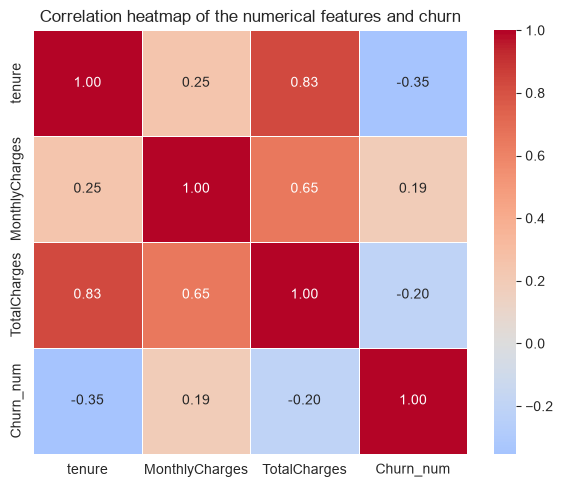


Strongest pair: ('tenure', 'TotalCharges') -> 0.83


In [3]:
corr = d[num_cols + ["Churn_num"]].corr()
print(corr.round(2))

plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Correlation heatmap of the numerical features and churn")
plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
strongest = pairs.abs().idxmax()
print()
print("Strongest pair:", strongest, "->", round(pairs[strongest], 2))

**What the code does:** It calculates the correlation matrix of tenure, MonthlyCharges, TotalCharges and a numeric version of Churn (1 for Yes), draws it as a heatmap with the values written in the cells, and prints the strongest pair.

**Why this method was used:** A heatmap shows the whole matrix at once, and a diverging color scale centered at 0 makes the sign of each relationship visible. A numeric version of the target lets me include it in the matrix.

**What the output means:** The strongest pair is tenure and TotalCharges (about 0.83). MonthlyCharges and TotalCharges are about 0.65, and tenure and MonthlyCharges about 0.25. Tenure and Churn have a moderate negative correlation of about -0.35, TotalCharges and Churn about -0.20, and MonthlyCharges and Churn about +0.19.

**Insights:** Tenure and TotalCharges are strongly related because TotalCharges is built from tenure and the monthly price, so they are a multicollinearity risk. Tenure is the numerical feature most related to churn, and longer tenure goes with less churn. This is a correlation and not a proof of a cause.

**Effect on the ML pipeline:** For a linear model one of tenure and TotalCharges should be dropped or combined, or a tree based model can be used. Tenure should be kept as a key feature.

### Exercise 2: Detect outliers using IQR

          feature      Q1       Q3      IQR  lower_limit  upper_limit  \
0          tenure    9.00    55.00    46.00       -60.00       124.00   
1  MonthlyCharges   35.50    89.85    54.35       -46.02       171.38   
2    TotalCharges  401.45  3794.74  3393.29     -4688.48      8884.67   

   outliers  data_min  data_max  
0         0      0.00     72.00  
1         0     18.25    118.75  
2         0     18.80   8684.80  


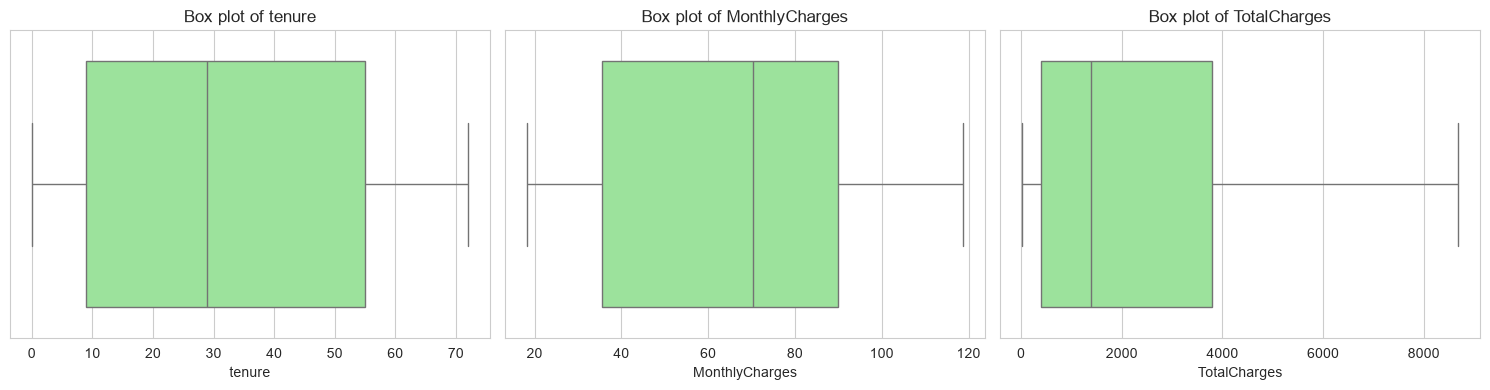

In [4]:
rows = []
for c in num_cols:
    s = d[c].dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((s < low) | (s > high)).sum())
    rows.append([c, round(q1, 2), round(q3, 2), round(iqr, 2), round(low, 2), round(high, 2),
                 n_out, round(s.min(), 2), round(s.max(), 2)])

iqr_table = pd.DataFrame(rows, columns=["feature", "Q1", "Q3", "IQR", "lower_limit", "upper_limit",
                                        "outliers", "data_min", "data_max"])
print(iqr_table)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, num_cols):
    sns.boxplot(x=d[c], ax=ax, color="lightgreen")
    ax.set_title("Box plot of " + c)
plt.tight_layout()
plt.show()

**What the code does:** For each numerical column it calculates Q1, Q3 and the IQR, the lower and upper limits, counts the values outside the limits, and shows the real minimum and maximum next to the limits. Then it draws one box plot per column. It uses the numeric copy of TotalCharges.

**Why this method was used:** The IQR method does not assume a bell shaped distribution, which suits these columns because none of them is bell shaped. Showing the data minimum and maximum next to the limits shows how far the data is from them.

**What the output means:** No value is outside the limits in any of the three columns. For TotalCharges the upper limit is about 8884 while the largest value is about 8685, so even the biggest value is inside. The box plots show no dots beyond the whiskers.

**Insights:** There are no univariate outliers. TotalCharges is right skewed, but its long tail is smooth and not made of isolated points, so skew should not be confused with outliers.

**Effect on the ML pipeline:** No rows need to be removed because of outliers, so no information is lost. The skew of TotalCharges is a separate question for transformation in the preprocessing sprint.

### Exercise 3: Analyze the distribution of a numerical feature

I chose TotalCharges.

mean                  2283.30
median                1397.48
mode                    20.20
standard deviation    2266.77
IQR                   3393.29
skewness                 0.96
kurtosis (excess)       -0.23
dtype: float64


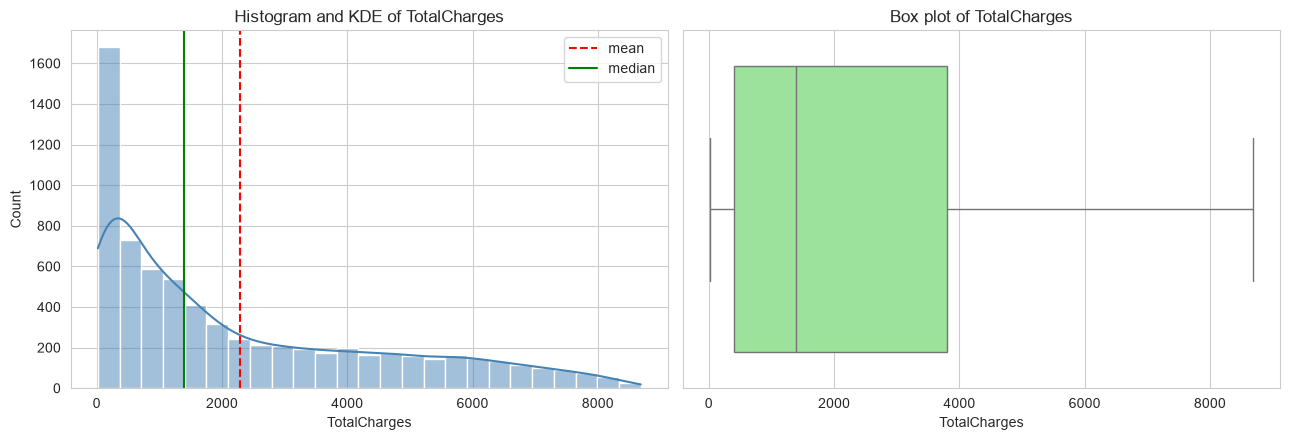

In [5]:
feature = "TotalCharges"
s = d[feature].dropna()

summary = pd.Series({
    "mean": s.mean(),
    "median": s.median(),
    "mode": s.mode()[0],
    "standard deviation": s.std(),
    "IQR": s.quantile(0.75) - s.quantile(0.25),
    "skewness": s.skew(),
    "kurtosis (excess)": s.kurt(),
})
print(summary.round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(s, kde=True, ax=axes[0], color="steelblue")
axes[0].axvline(s.mean(), color="red", linestyle="--", label="mean")
axes[0].axvline(s.median(), color="green", label="median")
axes[0].set_title("Histogram and KDE of " + feature)
axes[0].legend()
sns.boxplot(x=s, ax=axes[1], color="lightgreen")
axes[1].set_title("Box plot of " + feature)
plt.tight_layout()
plt.show()

**What the code does:** It calculates the mean, median, mode, standard deviation, IQR, skewness and kurtosis of TotalCharges and draws a histogram with a KDE curve and lines for the mean and the median, and a box plot.

**Why this method was used:** The statistics give exact numbers for the center, the spread and the shape, and the plots show the shape directly. I chose TotalCharges because it is the feature with the clearest skew.

**What the output means:** The mean (about 2283) is far above the median (about 1397), the standard deviation is about 2267 (as large as the mean), the skewness is about 0.96 and the excess kurtosis is about -0.2. The histogram has one tall peak near zero and a long tail to the right.

**Insights:** TotalCharges is moderately to highly right skewed, because it grows with tenure and many customers are new. The center is better described by the median than by the mean, the spread is very wide, there are no outliers in the box plot, and the shape is not normal.

**Effect on the ML pipeline:** Methods that assume a bell shape should not be used on the raw values. A square root or a log transformation can be tested in the preprocessing sprint for models that are sensitive to skew, and the feature will need scaling because its range is much larger than the other features.

### Exercise 4: Perform categorical analysis

Unique categories of each categorical feature:
gender              2
SeniorCitizen       2
Partner             2
Dependents          2
PhoneService        2
PaperlessBilling    2
InternetService     3
MultipleLines       3
OnlineSecurity      3
OnlineBackup        3
TechSupport         3
DeviceProtection    3
StreamingTV         3
StreamingMovies     3
Contract            3
PaymentMethod       4

Contract
                count  percent
Contract                      
Month-to-month   3875     55.0
Two year         1695     24.1
One year         1473     20.9

InternetService
                 count  percent
InternetService                
Fiber optic       3096     44.0
DSL               2421     34.4
No                1526     21.7

PaymentMethod
                           count  percent
PaymentMethod                            
Electronic check            2365     33.6
Mailed check                1612     22.9
Bank transfer (automatic)   1544     21.9
Credit card (automatic)     1522  

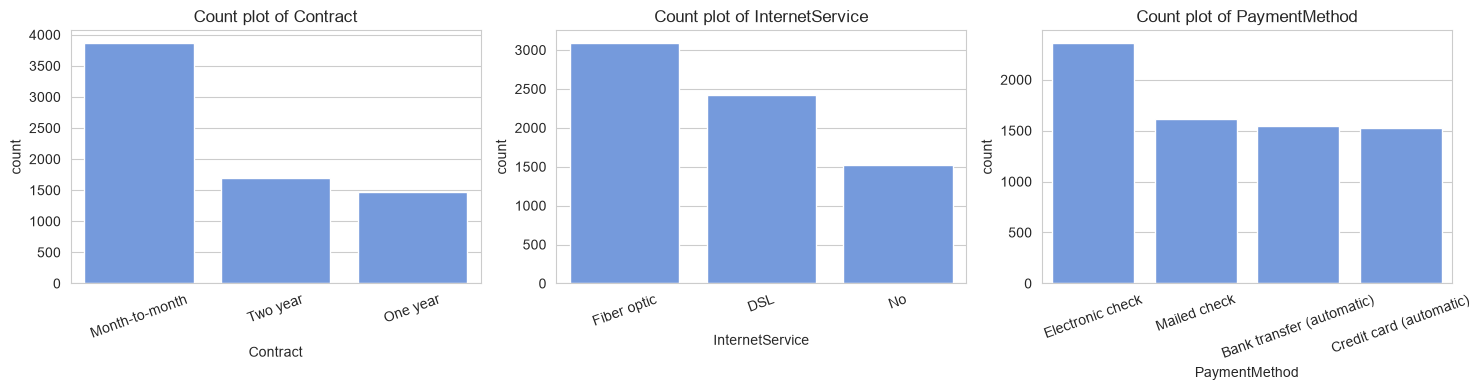


Churn rate (%) of each category of Contract and PaymentMethod:
Contract
Month-to-month    42.7
One year          11.3
Two year           2.8

PaymentMethod
Bank transfer (automatic)    16.7
Credit card (automatic)      15.2
Electronic check             45.3
Mailed check                 19.1



In [6]:
cat_features = [c for c in df.columns if c not in ["customerID", "Churn", "tenure", "MonthlyCharges", "TotalCharges"]]

print("Unique categories of each categorical feature:")
print(df[cat_features].nunique().sort_values().to_string())

five = ["Contract", "InternetService", "PaymentMethod", "PhoneService", "gender"]
for c in five:
    counts = df[c].value_counts()
    print()
    print(c)
    print(pd.DataFrame({"count": counts, "percent": (counts / len(df) * 100).round(1)}))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, ["Contract", "InternetService", "PaymentMethod"]):
    sns.countplot(data=df, x=c, order=df[c].value_counts().index, ax=ax, color="cornflowerblue")
    ax.set_title("Count plot of " + c)
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

print()
print("Churn rate (%) of each category of Contract and PaymentMethod:")
for c in ["Contract", "PaymentMethod"]:
    print((d.groupby(c)["Churn_num"].mean() * 100).round(1).to_string())
    print()

**What the code does:** It counts the unique categories of every categorical feature, prints the frequency and percentage tables of five features, draws count plots for three of them, and then shows the churn rate of each category of Contract and PaymentMethod.

**Why this method was used:** Frequency tables give exact shares, count plots show the size differences quickly, and the churn rates connect the categorical features with the target.

**What the output means:** All 16 categorical features have between 2 and 4 categories. Month-to-month contracts are about 55 percent of the customers, Fiber optic is the largest internet service group (about 44 percent), and electronic check is the largest payment method. Gender is split almost equally, and about 90 percent of the customers have phone service. The churn rate is about 43 percent for month-to-month contracts against about 3 percent for two year contracts, and electronic check users churn the most among the payment methods.

**Insights:** The categorical features have low cardinality and no rare categories. Contract and payment method separate churners from non-churners clearly, while gender and phone service are dominated by one label or evenly split and carry little information.

**Effect on the ML pipeline:** One-hot encoding is safe for all these features and will not create too many columns. Contract is likely to be one of the strongest features, and the weak ones can be tested for removal during feature selection.

### Exercise 5: Generate a complete EDA summary

The function eda_summary takes a DataFrame and the name of the target column and prints the shape and data types, the numerical, categorical and identifier columns, the missing values (including hidden blank strings), the duplicates, the statistics and IQR outliers of the numerical columns, the categories of the categorical columns, the target distribution and imbalance ratio, and the three numerical features most correlated with the target. It works on a copy, so the DataFrame that is passed in is not changed.

In [7]:
def eda_summary(data, target):
    # work on a copy, so the DataFrame that was passed in is never changed
    d_ = data.copy()
    n_rows, n_cols = d_.shape

    # 1. hidden blank strings in text columns become NaN (they are counted first)
    text_cols_ = [c for c in d_.columns if not pd.api.types.is_numeric_dtype(d_[c])]
    blank_counts = {}
    for c in text_cols_:
        is_blank = d_[c].astype(str).str.strip() == ""
        blank_counts[c] = int(is_blank.sum())
        d_.loc[is_blank, c] = np.nan

    # 2. text columns that really hold numbers (at least 95 percent convertible) become numeric
    converted_cols = []
    for c in text_cols_:
        non_null = d_[c].notna().sum()
        if non_null > 0:
            as_number = pd.to_numeric(d_[c], errors="coerce")
            if as_number.notna().sum() / non_null >= 0.95:
                d_[c] = as_number
                converted_cols.append(c)

    # 3. rule for the column roles:
    #    identifier = (almost) every value is unique and the column is not a decimal number
    #    numerical  = numeric column with more than 10 different values
    #    categorical = everything else (text, or numbers with few different values)
    others = [c for c in d_.columns if c != target]
    identifier_cols = [c for c in others
                       if d_[c].nunique() / n_rows > 0.95 and not pd.api.types.is_float_dtype(d_[c])]
    numeric_cols = [c for c in others
                    if c not in identifier_cols and pd.api.types.is_numeric_dtype(d_[c]) and d_[c].nunique() > 10]
    categorical_cols = [c for c in others if c not in identifier_cols + numeric_cols]

    print("=" * 60)
    print("EDA SUMMARY")
    print("=" * 60)
    print("Shape:", n_rows, "rows,", n_cols, "columns")
    print("Data types:", data.dtypes.astype(str).value_counts().to_dict())
    print("Numerical columns:", numeric_cols)
    print("Categorical columns:", categorical_cols)
    print("Identifier columns:", identifier_cols)
    print("Target:", target)
    if converted_cols:
        print("Text columns converted to numbers for this summary:", converted_cols)

    # missing values
    print()
    print("MISSING VALUES")
    missing = d_.isnull().sum()
    missing = missing[missing > 0]
    if len(missing) == 0:
        print("none")
    else:
        table = pd.DataFrame({"missing": missing, "percent": (missing / n_rows * 100).round(2)})
        print(table.sort_values("missing", ascending=False))
    hidden = {c: n for c, n in blank_counts.items() if n > 0}
    print("Hidden blank strings found (column: count):", hidden if hidden else "none")

    # duplicates
    print()
    print("DUPLICATES")
    print("Completely duplicated rows:", int(d_.duplicated().sum()))
    for c in identifier_cols:
        print("Duplicated values in identifier", c + ":", int(d_[c].duplicated().sum()))
    if identifier_cols:
        without_id = [c for c in d_.columns if c not in identifier_cols]
        print("Rows identical except for the identifier columns:", int(d_.duplicated(subset=without_id).sum()))

    # numerical columns
    print()
    print("NUMERICAL COLUMNS")
    rows = []
    for c in numeric_cols:
        s = d_[c].dropna()
        q1, q3 = s.quantile(0.25), s.quantile(0.75)
        iqr = q3 - q1
        n_out = int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())
        rows.append([c, round(s.mean(), 2), round(s.median(), 2), round(s.std(), 2), round(s.skew(), 2), n_out])
    if rows:
        print(pd.DataFrame(rows, columns=["column", "mean", "median", "std", "skewness", "IQR_outliers"]).to_string(index=False))
    else:
        print("none")

    # categorical columns
    print()
    print("CATEGORICAL COLUMNS")
    rows = []
    for c in categorical_cols:
        share = d_[c].value_counts(normalize=True) * 100
        if len(share) == 0:
            rows.append([c, 0, "all values missing", 0.0])
        else:
            rows.append([c, int(d_[c].nunique()), str(share.index[0]), round(share.iloc[0], 1)])
    if rows:
        print(pd.DataFrame(rows, columns=["column", "categories", "most_frequent", "its_percent"]).to_string(index=False))
    else:
        print("none")

    # target
    print()
    print("TARGET:", target)
    y = d_[target]
    if y.nunique() <= 10:
        counts = y.value_counts()
        print(pd.DataFrame({"count": counts, "percent": (counts / counts.sum() * 100).round(1)}))
        print("Imbalance ratio (largest : smallest):", round(counts.max() / counts.min(), 2), ": 1")
        positive = counts.idxmin()
        y_num = (y == positive).astype(int)
        print("Positive class for the correlation:", positive)
    else:
        print(y.describe().round(2))
        y_num = y

    # numerical features most correlated with the numeric target
    print()
    print("THREE NUMERICAL FEATURES MOST CORRELATED WITH THE TARGET")
    if numeric_cols:
        corr = d_[numeric_cols].corrwith(y_num)
        top = corr.reindex(corr.abs().sort_values(ascending=False).index).head(3)
        print(top.round(3).to_string())
    else:
        print("no numerical columns")
    print("=" * 60)

df_before = df.copy()
eda_summary(df, "Churn")
print()
print("The DataFrame passed to the function is unchanged:", df.equals(df_before))

EDA SUMMARY
Shape: 7043 rows, 21 columns
Data types: {'str': 18, 'int64': 2, 'float64': 1}
Numerical columns: ['tenure', 'MonthlyCharges', 'TotalCharges']
Categorical columns: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Identifier columns: ['customerID']
Target: Churn
Text columns converted to numbers for this summary: ['TotalCharges']

MISSING VALUES
              missing  percent
TotalCharges       11     0.16
Hidden blank strings found (column: count): {'TotalCharges': 11}

DUPLICATES
Completely duplicated rows: 0
Duplicated values in identifier customerID: 0
Rows identical except for the identifier columns: 22

NUMERICAL COLUMNS
        column    mean  median     std  skewness  IQR_outliers
        tenure   32.37   29.00   24.56      0.24             0
MonthlyCharges   64.

**What the code does:** The function works on a copy of the data. It replaces blank strings by NaN, converts text columns that hold numbers, decides the role of each column with a simple rule (written in the comments), and prints the shape, types, missing values, duplicates, statistics and IQR outliers of the numerical columns, the categories of the categorical columns, the target distribution and imbalance ratio, and the three numerical features most correlated with the target. The last lines call it on the Telco data and check that the original DataFrame was not changed.

**Why this method was used:** Putting the whole routine in one function makes the EDA repeatable for any dataset, and the copy protects the original data. The role rule is simple on purpose, so that I can explain it.

**What the output means:** The summary reports 7043 rows and 21 columns, 3 numerical columns, 16 categorical columns and customerID as the identifier. TotalCharges is converted to numbers and shows 11 missing values, and the hidden blank strings are reported as 11 in TotalCharges. There are no complete duplicates and no repeated ids, and the IQR outlier count is 0 for the numerical columns. The target Churn has a ratio of about 2.8 to 1, and the numerical features most correlated with churn are tenure, TotalCharges and MonthlyCharges. The check at the end shows True, so the original data is unchanged.

**Insights:** One call gives the main facts of the data that I found in the other notebooks, including the hidden missing values and the class imbalance.

**Effect on the ML pipeline:** The function can be used as a first quality check at the start of any future project and before every model, so that data problems are found before training.